# BMW Sales Analysis


This notebook explores BMW sales data from 2010 to 2024 to understand patterns in pricing, mileage, model popularity, regional sales, and sales classification.

### Dataset Overview

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

In [2]:
df = pd.read_csv('data\\BMW sales data (2010-2024).csv')

In [3]:
df.head(5)

,Model,Year,Region,Color,Fuel_Type,Transmission,Engine_Size_L,Mileage_KM,Price_USD,Sales_Volume,Sales_Classification
0,5 Series,2016,Asia,Red,Petrol,Manual,3.5,151748,98740,8300,High
1,i8,2013,North America,Red,Hybrid,Automatic,1.6,121671,79219,3428,Low
2,5 Series,2022,North America,Blue,Petrol,Automatic,4.5,10991,113265,6994,Low
3,X3,2024,Middle East,Blue,Petrol,Automatic,1.7,27255,60971,4047,Low
4,7 Series,2020,South America,Black,Diesel,Manual,2.1,122131,49898,3080,Low


In [4]:
df.shape

(50000, 11)

The dataset contains 50,000 rows and 11 columns.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Model                 50000 non-null  str    
 1   Year                  50000 non-null  int64  
 2   Region                50000 non-null  str    
 3   Color                 50000 non-null  str    
 4   Fuel_Type             50000 non-null  str    
 5   Transmission          50000 non-null  str    
 6   Engine_Size_L         50000 non-null  float64
 7   Mileage_KM            50000 non-null  int64  
 8   Price_USD             50000 non-null  int64  
 9   Sales_Volume          50000 non-null  int64  
 10  Sales_Classification  50000 non-null  str    
dtypes: float64(1), int64(4), str(6)
memory usage: 4.2 MB


In [6]:
df.describe()

,Year,Engine_Size_L,Mileage_KM,Price_USD,Sales_Volume
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,2017.015700,3.247180,100307.203140,75034.600900,5067.514680
std,4.324459,1.009078,57941.509344,25998.248882,2856.767125
min,2010.000000,1.500000,3.000000,30000.000000,100.000000
25%,2013.000000,2.400000,50178.000000,52434.750000,2588.000000
50%,2017.000000,3.200000,100388.500000,75011.500000,5087.000000
75%,2021.000000,4.100000,150630.250000,97628.250000,7537.250000
max,2024.000000,5.000000,199996.000000,119998.000000,9999.000000


### Data Cleaning and Quality Checks

In [7]:
df.isna().sum()

Model                   0
Year                    0
Region                  0
Color                   0
Fuel_Type               0
Transmission            0
Engine_Size_L           0
Mileage_KM              0
Price_USD               0
Sales_Volume            0
Sales_Classification    0
dtype: int64

No missing values were found. 

In [8]:
df.duplicated().sum()

np.int64(0)

No duplicate rows were found.

In [9]:
categorical_cols = ["Model", "Region", "Color", "Fuel_Type", "Transmission", "Sales_Classification"]

pd.DataFrame({
    "Column": categorical_cols,
    "Unique Values": [df[col].nunique() for col in categorical_cols],
    "Values": [", ".join(df[col].unique()) for col in categorical_cols]
})

,Column,Unique Values,Values
0,Model,11,"5 Series, i8, X3, 7 Series, M5, 3 Series, X1, ..."
1,Region,6,"Asia, North America, Middle East, South Americ..."
2,Color,6,"Red, Blue, Black, Silver, White, Grey"
3,Fuel_Type,4,"Petrol, Hybrid, Diesel, Electric"
4,Transmission,2,"Manual, Automatic"
5,Sales_Classification,2,"High, Low"


The categorical columns have a manageable number of unique values, making them suitable for further analysis.

In [10]:
df['Sales_Classification'].value_counts(normalize=True) * 100

Sales_Classification
Low     69.508
High    30.492
Name: proportion, dtype: float64

Most records are classified as Low sales, while about 30% are classified as High sales.

### Exploratory Data Analysis

* How does sales volume change over time?

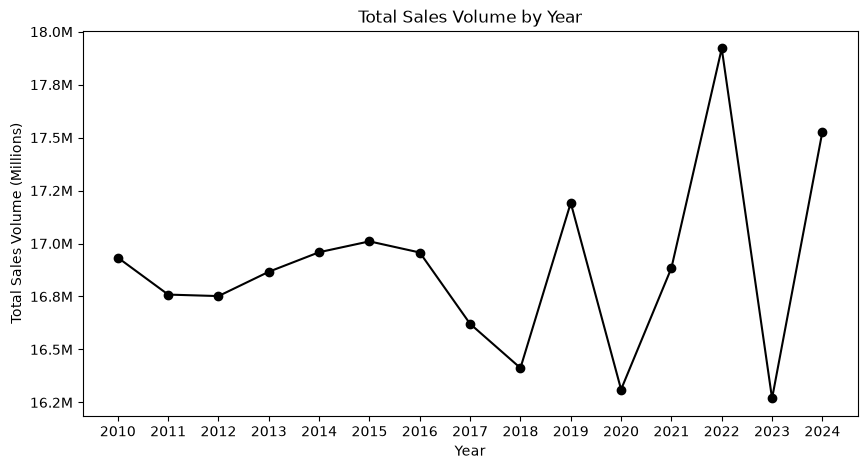

In [ ]:
yearly_sales = df.groupby("Year")["Sales_Volume"].sum()
yearly_sales.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Total Sales Volume by Year",
    color="black",
)
plt.xlabel("Year")
plt.ylabel("Total Sales Volume (Millions)")
plt.xticks(yearly_sales.index)
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M")
)
plt.show()

* Which BMW models have the highest total sales volume?

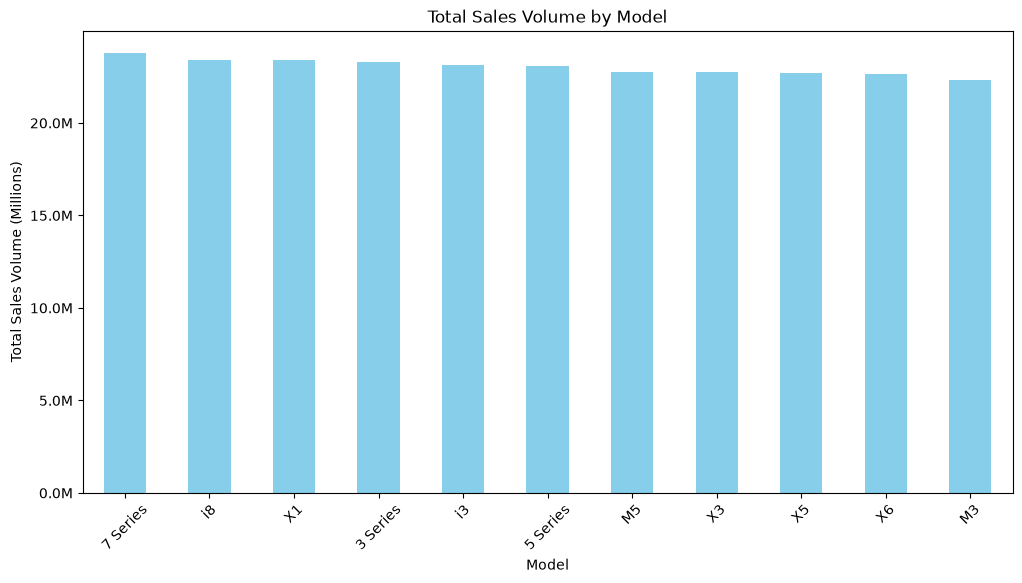

In [35]:
models = df.groupby("Model")["Sales_Volume"].sum().sort_values(ascending=False)
models.plot(
    kind="bar",
    figsize=(12, 6),
    title="Total Sales Volume by Model",
    color="skyblue",
)   
plt.ylabel("Total Sales Volume (Millions)")
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M")
)
plt.xticks(rotation=45)
plt.show()

* Which regions have the highest percentage of High sales?

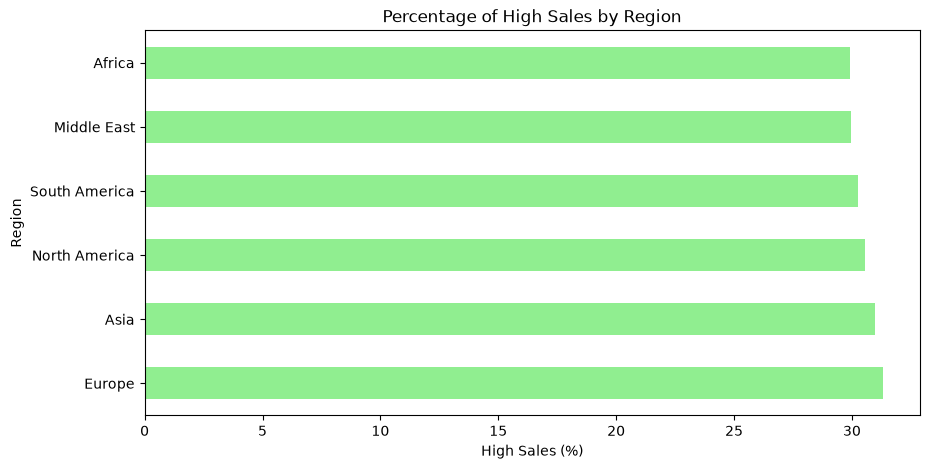

In [59]:
region_high_sales = (
    df.assign(Is_High_Sales=df["Sales_Classification"] == "High")
      .groupby("Region")["Is_High_Sales"]
      .mean()
      .sort_values(ascending=False) * 100
)

region_high_sales.plot(
    kind="barh",
    figsize=(10, 5),
    title="Percentage of High Sales by Region",
    color="lightgreen"
)

plt.ylabel("Region")
plt.xlabel("High Sales (%)")
plt.yticks(rotation=0)
plt.show()

### EDA Summary

The yearly sales volume fluctuates between 2010 and 2024, reaching its highest point in 2022 and lowest point in 2023. However, the overall range is relatively narrow, suggesting that total sales volume remains fairly stable over time.

The 7 Series has the highest total sales volume, while the M3 has the lowest. The difference between models is not very large, so no single BMW model strongly dominates the dataset.

Europe has the highest percentage of High sales at about 31.3%, followed closely by Asia and North America. Since the regional percentages are very similar, High sales appear to be fairly evenly distributed across regions.

### Final Conclusions



This analysis explored BMW sales data from 2010 to 2024, focusing on sales volume, model performance, regional differences, pricing, and sales classification.

The dataset is clean, with no missing values or duplicate rows. It contains 50,000 records and 11 columns, making it suitable for exploratory analysis.

Sales volume remains relatively stable over time, with the highest total sales volume in 2022 and the lowest in 2023. Differences between BMW models are also fairly small, although the 7 Series has the highest total sales volume and the M3 has the lowest.

High sales are fairly evenly distributed across regions. Europe has the highest percentage of High sales, but the difference between regions is small.

Overall, the dataset shows balanced patterns across models, regions, and categories. Some relationships, such as model and price, appear weaker than expected, which may indicate that the dataset is synthetic or does not fully capture real-world BMW market behavior.